In [1]:
import pandas as pd

file_path = r"C:\Users\lucky\Downloads\Ted_dataset\2020-05-01\ted_talks_en.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (4005, 19)


In [2]:
# Display column names
print("Column names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset information:")
df.info()

# Display basic statistics
print("\nNumerical summary:")
print(df.describe())

# Display first five records
df.head()

Column names:
['talk_id', 'title', 'speaker_1', 'all_speakers', 'occupations', 'about_speakers', 'views', 'recorded_date', 'published_date', 'event', 'native_lang', 'available_lang', 'comments', 'duration', 'topics', 'related_talks', 'url', 'description', 'transcript']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 4005 entries, 0 to 4004
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   talk_id         4005 non-null   int64  
 1   title           4005 non-null   str    
 2   speaker_1       4005 non-null   str    
 3   all_speakers    4001 non-null   str    
 4   occupations     3483 non-null   str    
 5   about_speakers  3502 non-null   str    
 6   views           4005 non-null   int64  
 7   recorded_date   4004 non-null   str    
 8   published_date  4005 non-null   str    
 9   event           4005 non-null   str    
 10  native_lang     4005 non-null   str    
 11  available_lang  4005 n

,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,2006-02-25,2006-06-27,TED2006,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",272.0,977,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre..."
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,2006-02-22,2006-06-27,TED2006,en,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",628.0,1190,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832,2006-02-24,2006-06-27,TED2006,en,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr...",124.0,1286,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069,2006-02-26,2006-06-27,TED2006,en,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es...",219.0,1116,"['MacArthur grant', 'activism', 'business', 'c...",{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954,2006-02-25,2006-06-27,TED2006,en,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs...",4931.0,1164,"['children', 'creativity', 'culture', 'dance',...","{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...


In [3]:
print("Missing values before cleaning:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values before cleaning:
talk_id             0
title               0
speaker_1           0
all_speakers        4
occupations       522
about_speakers    503
views               0
recorded_date       1
published_date      0
event               0
native_lang         0
available_lang      0
comments          655
duration            0
topics              0
related_talks       0
url                 0
description         0
transcript          0
dtype: int64

Total missing values: 1685
Duplicate rows: 0


In [4]:
# Replace missing speaker-related text with "Unknown"
text_columns = [
    "all_speakers",
    "occupations",
    "about_speakers"
]

for col in text_columns:
    df[col] = df[col].fillna("Unknown")

# Replace missing comment counts with 0
df["comments"] = df["comments"].fillna(0)

print("Missing values handled.")

Missing values handled.


In [5]:
# Convert date strings into datetime format
df["recorded_date"] = pd.to_datetime(
    df["recorded_date"], errors="coerce"
)

df["published_date"] = pd.to_datetime(
    df["published_date"], errors="coerce"
)

print("Date columns converted successfully.")
print(df[["recorded_date", "published_date"]].dtypes)

Date columns converted successfully.
recorded_date     datetime64[us]
published_date    datetime64[us]
dtype: object


In [6]:
print("Dataset shape after cleaning:", df.shape)

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows after cleaning:", df.duplicated().sum())

Dataset shape after cleaning: (4005, 19)

Missing values after cleaning:
talk_id           0
title             0
speaker_1         0
all_speakers      0
occupations       0
about_speakers    0
views             0
recorded_date     1
published_date    0
event             0
native_lang       0
available_lang    0
comments          0
duration          0
topics            0
related_talks     0
url               0
description       0
transcript        0
dtype: int64

Duplicate rows after cleaning: 0


In [7]:
output_path = (
    r"C:\Users\lucky\Downloads\Ted_dataset\2020-05-01"
    r"\ted_talks_cleaned.csv"
)

df.to_csv(output_path, index=False)

print("Cleaned dataset saved to:", output_path)

Cleaned dataset saved to: C:\Users\lucky\Downloads\Ted_dataset\2020-05-01\ted_talks_cleaned.csv


In [8]:
print("Missing recorded dates:", df["recorded_date"].isnull().sum())

print(df[df["recorded_date"].isnull()][["title", "speaker_1", "recorded_date"]])

Missing recorded dates: 1
                                                  title       speaker_1  \
3831  The unpaid work that GDP ignores -- and why it...  Marilyn Waring   

     recorded_date  
3831           NaT  


In [10]:
output_path = r"C:\Users\lucky\Downloads\Ted_dataset\2020-05-01\ted_talks_cleaned.csv"

df.to_csv(output_path, index=False)

print("Updated cleaned dataset saved successfully!")

Updated cleaned dataset saved successfully!


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

file_path = r"C:\Users\lucky\Downloads\Ted_dataset\2020-05-01\ted_talks_cleaned.csv"

df = pd.read_csv(file_path, parse_dates=["recorded_date", "published_date"])

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (4005, 19)


In [17]:
top_talks = df.nlargest(10, "views")[["title", "speaker_1", "views"]]

top_talks
 

,title,speaker_1,views
4,Do schools kill creativity?,Sir Ken Robinson,65051954
1296,Your body language may shape who you are,Amy Cuddy,57074270
2062,This is what happens when you reply to spam email,James Veitch,56932551
646,How great leaders inspire action,Simon Sinek,49730580
796,The power of vulnerability,Brené Brown,47544833
1724,How to speak so that people want to listen,Julian Treasure,41504331
2108,Inside the mind of a master procrastinator,Tim Urban,37976820
1366,"Looks aren't everything. Believe me, I'm a model.",Cameron Russell,33874546
2724,My philosophy for a happy life,Sam Berns,33691484
1898,The next outbreak? We're not ready,Bill Gates,33521780


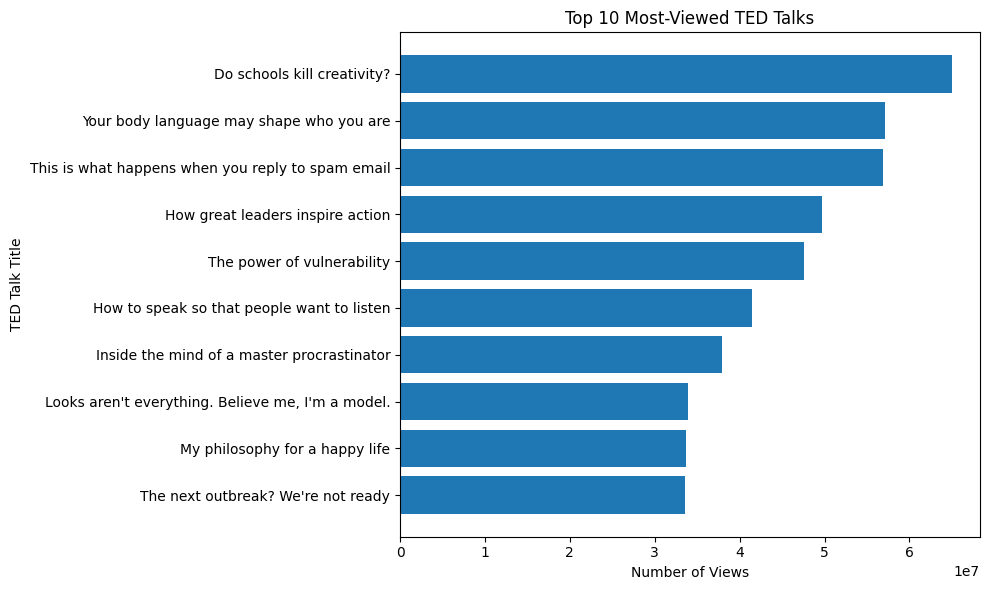

In [18]:
top_talks = df.nlargest(10, "views")[["title", "speaker_1", "views"]]

plt.figure(figsize=(10, 6))
plt.barh(top_talks["title"][::-1], top_talks["views"][::-1])

plt.xlabel("Number of Views")
plt.ylabel("TED Talk Title")
plt.title("Top 10 Most-Viewed TED Talks")
plt.tight_layout()
plt.show()

speaker_1
Alex Gendler        117619583
Sir Ken Robinson     84380518
James Veitch         78843641
Simon Sinek          62661183
Brené Brown          61285977
Bill Gates           57107176
Amy Cuddy            57074270
Julian Treasure      54799681
Hans Rosling         39871561
Tim Urban            37976820
Name: views, dtype: int64


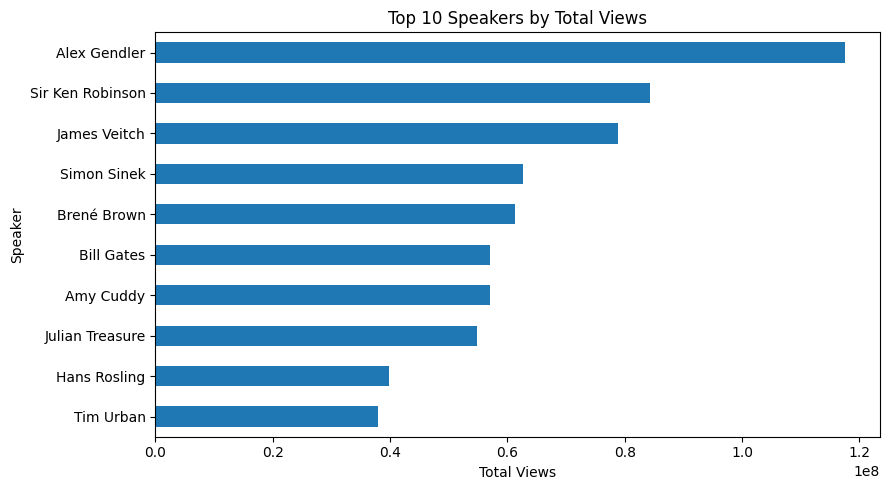

In [15]:
top_speakers = (
    df.groupby("speaker_1")["views"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_speakers)
top_speakers.sort_values().plot(
    kind="barh", figsize=(9, 5)
)

plt.xlabel("Total Views")
plt.ylabel("Speaker")
plt.title("Top 10 Speakers by Total Views")
plt.tight_layout()
plt.show()

In [20]:
import ast
from collections import Counter

topic_counts = Counter()

for topics in df["topics"].dropna():
    try:
        parsed_topics = ast.literal_eval(topics)
        if isinstance(parsed_topics, list):
            topic_counts.update(parsed_topics)
    except (ValueError, SyntaxError):
        pass

topic_df = pd.DataFrame(
    topic_counts.most_common(10),
    columns=["Topic", "Talk Count"]
)

topic_df

,Topic,Talk Count
0,science,993
1,technology,979
2,culture,680
3,TEDx,581
4,global issues,574
5,TED-Ed,563
6,society,557
7,design,518
8,social change,512
9,animation,487


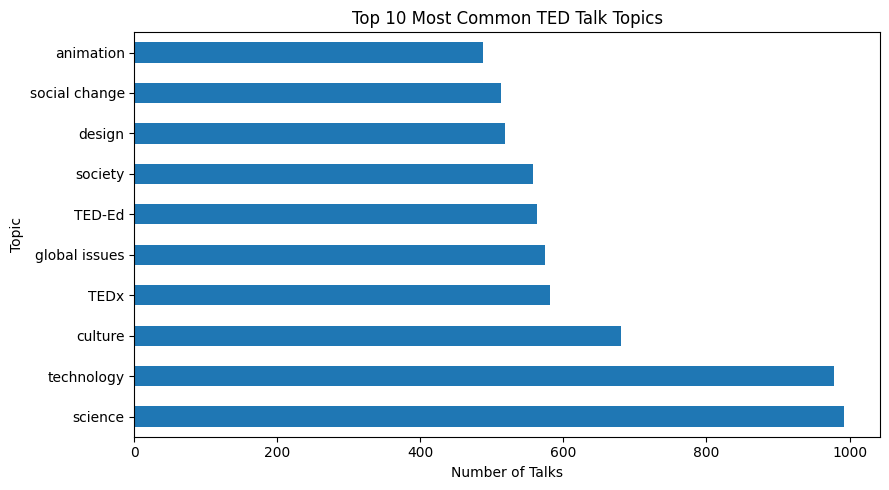

In [10]:
topic_df.plot(
    x="Topic",
    y="Talk Count",
    kind="barh",
    figsize=(9, 5),
    legend=False
)

plt.xlabel("Number of Talks")
plt.title("Top 10 Most Common TED Talk Topics")
plt.tight_layout()
plt.show()

TED Talk Duration Analysis
count    4005.00
mean       12.07
std         6.03
min         1.00
25%         6.55
50%        12.30
75%        16.23
max        65.37
Name: duration_minutes, dtype: float64


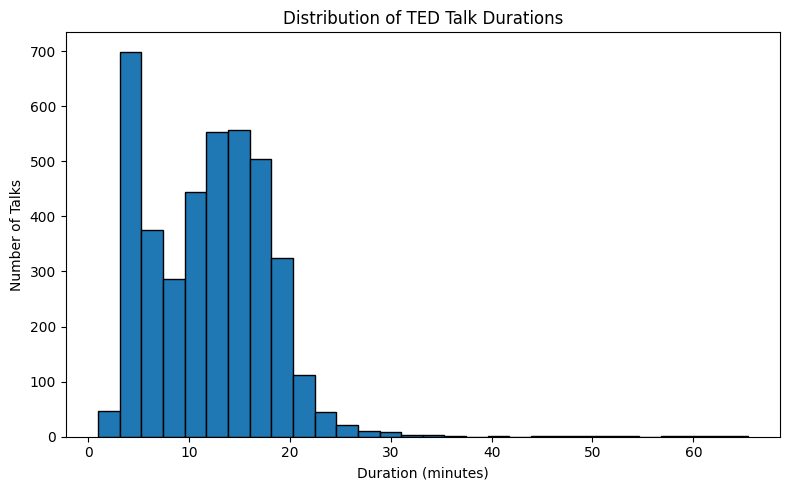

In [11]:
# Convert duration from seconds to minutes
df["duration_minutes"] = df["duration"] / 60

# Display duration statistics
print("TED Talk Duration Analysis")
print(df["duration_minutes"].describe().round(2))

plt.figure(figsize=(8, 5))

plt.hist(df["duration_minutes"], bins=30, edgecolor="black")

plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Talks")
plt.title("Distribution of TED Talk Durations")

plt.tight_layout()
plt.show()

published_year
2006     49
2007    119
2008    185
2009    215
2010    230
2011    255
2012    303
2013    242
2014    240
2015    220
2016    242
2017    315
2018    477
2019    702
2020    211
Name: count, dtype: int64


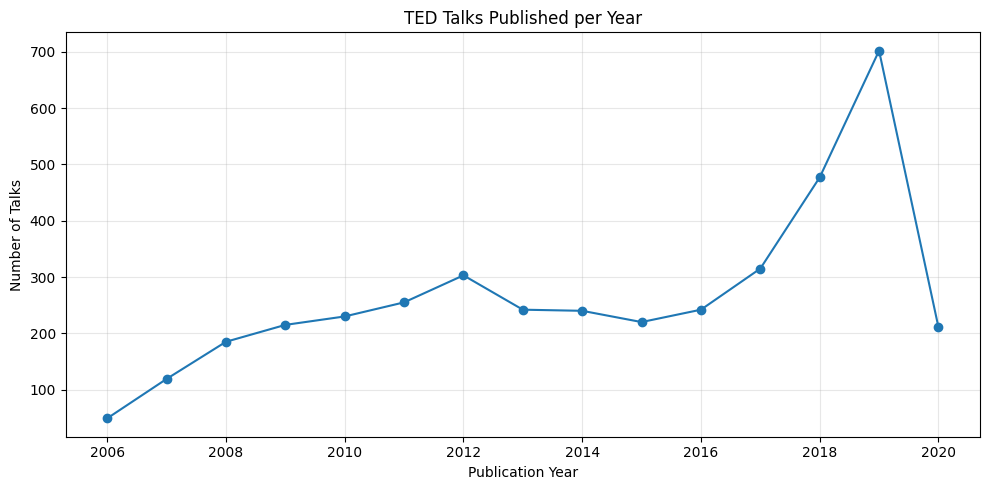

In [12]:
# Extract publication year
df["published_year"] = df["published_date"].dt.year

# Count talks published each year
yearly_talks = df["published_year"].value_counts().sort_index()

print(yearly_talks)

plt.figure(figsize=(10, 5))

plt.plot(yearly_talks.index, yearly_talks.values, marker="o")

plt.xlabel("Publication Year")
plt.ylabel("Number of Talks")
plt.title("TED Talks Published per Year")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Views statistics:
count        4005.00
mean      2148005.57
std       3451225.52
min             0.00
25%        882069.00
50%       1375508.00
75%       2133110.00
max      65051954.00
Name: views, dtype: float64

Comments statistics:
count    4005.00
mean      135.50
std       253.07
min         0.00
25%        17.00
50%        68.00
75%       162.00
max      6449.00
Name: comments, dtype: float64

Correlation between views and comments: 0.46


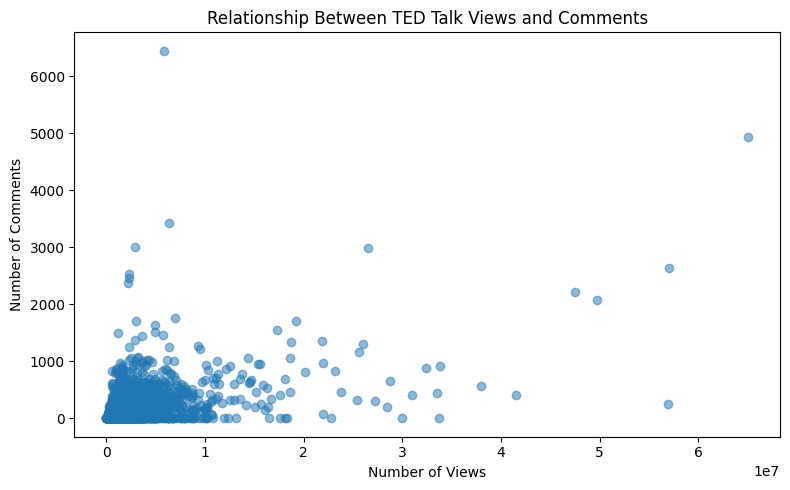

In [13]:
# Summary statistics for views and comments
print("Views statistics:")
print(df["views"].describe().round(2))

print("\nComments statistics:")
print(df["comments"].describe().round(2))

# Calculate correlation
correlation = df["views"].corr(df["comments"])

print("\nCorrelation between views and comments:", round(correlation, 3))

plt.figure(figsize=(8, 5))

plt.scatter(df["views"], df["comments"], alpha=0.5)

plt.xlabel("Number of Views")
plt.ylabel("Number of Comments")
plt.title("Relationship Between TED Talk Views and Comments")

plt.tight_layout()
plt.show()

In [14]:
output_folder = r"C:\Users\lucky\Downloads\Ted_dataset\2020-05-01"

top_talks.to_csv(output_folder + r"\top_10_talks.csv", index=False)
topic_df.to_csv(output_folder + r"\top_10_topics.csv", index=False)

print("EDA result tables saved successfully!")

EDA result tables saved successfully!
